# Battery EMS - House with on electrical vehicle

## Introduction

In today's rapidly evolving energy landscape, the integration of electric vehicles (EVs) into smart energy homes is emerging as a crucial strategy for sustainable energy management. As solar panels become an increasingly common feature in residential settings, the potential to harness and optimize solar excess energy offers a promising pathway to reduce reliance on the conventional power grid. By synchronizing EV charging with periods of high solar output, homeowners can not only maximize the use of clean, renewable energy but also achieve significant cost savings and contribute to a greener future.

Optimizing the charging process involves smart algorithms and energy management systems that dynamically balance energy supply and demand. In a smart energy home, this means intelligently scheduling EV recharge cycles to coincide with peak solar generation, thereby reducing energy waste and mitigating the environmental impact of fossil fuel-based power. Additionally, this integrated approach helps stabilize the local energy grid by smoothing out demand spikes and leveraging distributed energy resources more effectively.

As we develop and refine these optimization techniques, it is essential to recognize the transformative role that EVs play within the broader context of smart homes. They serve as both energy consumers and potential energy storage units, capable of supporting the household during times of low renewable generation. Embracing this dual functionality not only enhances energy resilience but also sets the stage for more advanced applications, such as vehicle-to-grid (V2G) services, further solidifying the link between sustainable transportation and smart energy solutions.

## Formulation and Solution

The solver adopted here is HiGHS. It is an open-source, high-performance optimization solver designed to handle linear programming (LP), 
mixed-integer programming (MIP), and quadratic programming (QP) problems efficiently. It provides state-of-the-art algorithms for 
solving large-scale optimization problems and is widely used in academia and industry.

Official Website: https://highs.dev/
GitHub Repository: https://github.com/ERGO-Code/HiGHS
Academic Paper: Hall, J. A. J., Huangfu, Q., & Miltenberger, M. (2020). HiGHS - A high-performance linear optimization solver. DOI: 10.48550/arXiv.2002.04030

In [1]:
import numpy as np
import highspy
import random

h = highspy.Highs()

### Parameters

In [2]:
T = 96  # 15-minute resolution: 24h * 4 = 96 periods
time_periods = list(range(T)) # Time periods

# Tariff values (€/kWh)
P1_Fora_Vazio = 0.30  # P1 tariff: Fora Vazio
P2_Vazio = 0.20       # P2 tariff: Vazio

# Build the consumption price array for a 24-hour period at 15-min resolution (96 periods):
# 00:00 - 08:00: 32 periods at P2 Vazio
# 08:00 - 22:00: 56 periods at P1 Fora Vazio
# 22:00 - 24:00: 8 periods at P2 Vazio
price_consumption = []
price_consumption += [P2_Vazio] * 32  # 00:00–08:00
price_consumption += [P1_Fora_Vazio] * 56  # 08:00–22:00
price_consumption += [P2_Vazio] * 8   # 22:00–24:00

# Forecasted house load and solar production (kWh per period)
# Construct a realistic forecast load profile for a weekday for a family of two
# with a fully electric house (including two baths) at 15-min resolution (96 periods).
forecast_load = []
forecast_load += [random.uniform(0.06, 0.1) for _ in range(24)]  # Nighttime: low base load
forecast_load += [random.uniform(0.06, 0.1) for _ in range(18)]   # Morning: peak load (breakfast, morning routines)
# forecast_load += [random.uniform(0.2, 0.4) for _ in range(26)]  # Daytime: lower load while at work
forecast_load += [random.uniform(0.06, 0.3) for _ in range(26)]  # Daytime: lower load while at work
forecast_load += [random.uniform(0.12, 0.5) for _ in range(16)]  # Evening: high load (dinner, cooking, baths)
forecast_load += [random.uniform(0.06, 0.1) for _ in range(12)]  # Late evening: moderate load

def solar_production(t, A):
    # Define active period: from period 36 (09:00) to period 72 (18:00)
    if t < 36 or t > 72:
        return 0.0
    else:
        # Cubic function: f(t) = a*t^3 + b*t^2 + c*t + d
        # Coefficients chosen such that:
        # f(36)=0, f(48)=A, f(72)=0, and f'(36)=0 for smooth sunrise.
        a = -A / 3456.0
        b = A / 24.0
        c = -1.875 * A
        d = 27 * A
        return a * t**3 + b * t**2 + c * t + d

# Parameters for the solar production cubic
A = 0.25  # Peak solar production (kWh per period) at noon (t=48)
eta = 0.9                    # Charging efficiency
P_charge = 3.4                 # Charging power (kW)
delta_t = 0.25               # 15 minutes in hours
lambda_penalty = list([0.01 for t in range(T)])
P_contract = 30              # Maximum power that can be drawn from the grid

# Build the forecast_solar array using the cubic function over the day
forecast_solar = [solar_production(t, A) for t in range(T)]

### Variables

In [3]:
print("Variables...")

# 1. Binary variable for charging power (dimensionless).
x = h.addVariables(time_periods,
                   upper=[1]*T,
                   name=["x_%d" % t for t in time_periods])
for t in time_periods:
    h.setInteger(x[t])

# 2. Binary variable for settlement: settle[t] = 1 means import is active, 0 means export is active.
settle_grid = h.addVariables(time_periods, upper=[1]*T, name=["settle_grid_%d" % t for t in time_periods])
for t in time_periods:
    h.setInteger(settle_grid[t])

# 3. Switching indicator for x: y[t], cost = switching penalty (set y_0 = 0).
y_x = h.addVariables(time_periods,
                   obj=[lambda_penalty[t] for t in time_periods],
                   upper=[1]*T,
                   name=["y_x_%d" % t for t in time_periods])
for t in time_periods:
   h.setInteger(y_x[t])

# 4. Battery charge, continuous.
charge = h.addVariables(time_periods, obj=[-P2_Vazio for t in time_periods],
                     upper=[delta_t * eta * P_charge]*T,  
                     name=["charge_%d" % t for t in time_periods])

# 5. Energy imported from the grid (kWh); cost = consumption price.
grid_in = h.addVariables(time_periods,
                         name=["grid_in_%d" % t for t in time_periods])

# 6. Energy injected into the grid (kWh); cost = -injection price.
grid_out = h.addVariables(time_periods,
                          obj=[0]*T,
                          name=["grid_out_%d" % t for t in time_periods])

grid_in_when_charging = h.addVariables(time_periods,
                                       obj=[price_consumption[t] for t in time_periods],
                                       lower=[0]*len(time_periods),
                                       name=["grid_in_charging_%d" % t for t in time_periods])

print("...done")

Variables...
...done


## Constraints

In [4]:
print("Constraints...")

# Boundary conditions:
h.addConstr(x[0] == x[1], name="x_initial")
h.addConstr(x[time_periods[-1]] == x[time_periods[-2]], name="x_final")

# 1. Battery charge energy
h.addConstrs(
    (charge[t] == delta_t * eta * P_charge * x[t]
     for t in time_periods),
    name=["Charge_calc_%d" % t for t in time_periods]
)

# 2. Energy balance at house
h.addConstrs(
    (grid_out[t] + forecast_load[t] + charge[t] == grid_in[t] + forecast_solar[t] for t in time_periods),
    name=["Bal_%d" % t for t in time_periods]
)

# 3. Contracted power limit
# Limit the energy imported from the grid in each period.
h.addConstrs((grid_in[t] <= P_contract * delta_t for t in time_periods),
             name=["ContractLimit_%d" % t for t in time_periods])

# 4. Settlement
# Add constraints to enforce that only one of grid_in and grid_out is nonzero:
M = 10.0
h.addConstrs((grid_in[t] <= M * settle_grid[t] for t in time_periods),
             name=["settle_grid_In_%d" % t for t in time_periods])
h.addConstrs((grid_out[t] <= M * (1 - settle_grid[t]) for t in time_periods),
             name=["settle_grid_Out_%d" % t for t in time_periods])

# 5. Switching Constraints (for t = 1,...,T-1)
h.addConstrs(
    (y_x[t] >= x[t-1] - x[t] for t in time_periods if t > 0),
    name=["y_x_calc1_%d" % t for t in time_periods if t > 0]
)
h.addConstrs(
    (y_x[t] >= x[t] - x[t-1] for t in time_periods if t > 0),
    name=["y_x_calc2_%d" % t for t in time_periods if t > 0]
)

for t in time_periods:
    h.addConstr(grid_in_when_charging[t] <= grid_in[t],
                name="GIC1_%d" % t)
    h.addConstr(grid_in_when_charging[t] <= M * x[t],
                name="GIC2_%d" % t)
    h.addConstr(grid_in_when_charging[t] >= grid_in[t] - M * (1 - x[t]),
                name="GIC3_%d" % t)

# 6. Forces at least 30 of charging
h.addConstrs((x[t] <= x[t-1] + x[t+1] for t in time_periods[1:-1]),
             name=["Neighbor_%d" % t for t in time_periods[1:-1]])
h.addConstr(x[0] <= x[1], name="Neighbor_0")
h.addConstr(x[time_periods[-1]] <= x[time_periods[-2]], name="Neighbor_%d" % time_periods[-1])

print("...done")

Constraints...
...done


### Set Objective and Solve

In [5]:
print("Solving...")

h.setMinimize()

status = h.writeModel("PV_plus_EV.lp")
print("writeModel status =", status)

# Backup original stdout.
output = h.solve()

solution = h.getSolution()
basis = h.getBasis()
info = h.getInfo()
model_status = h.getModelStatus()
print('Model status = ', h.modelStatusToString(model_status))
print()
print('Optimal objective = ', info.objective_function_value)
print('Iteration count = ', info.simplex_iteration_count)
print('Primal solution status = ', h.solutionStatusToString(info.primal_solution_status))
print('Dual solution status = ', h.solutionStatusToString(info.dual_solution_status))
print('Basis validity = ', h.basisValidityToString(info.basis_validity))

print("...done")


Solving...
writeModel status = HighsStatus.kOk
Model status =  Optimal

Optimal objective =  -0.0935538482525345
Iteration count =  7
Primal solution status =  Feasible
Dual solution status =  None
Basis validity =  Not valid
...done


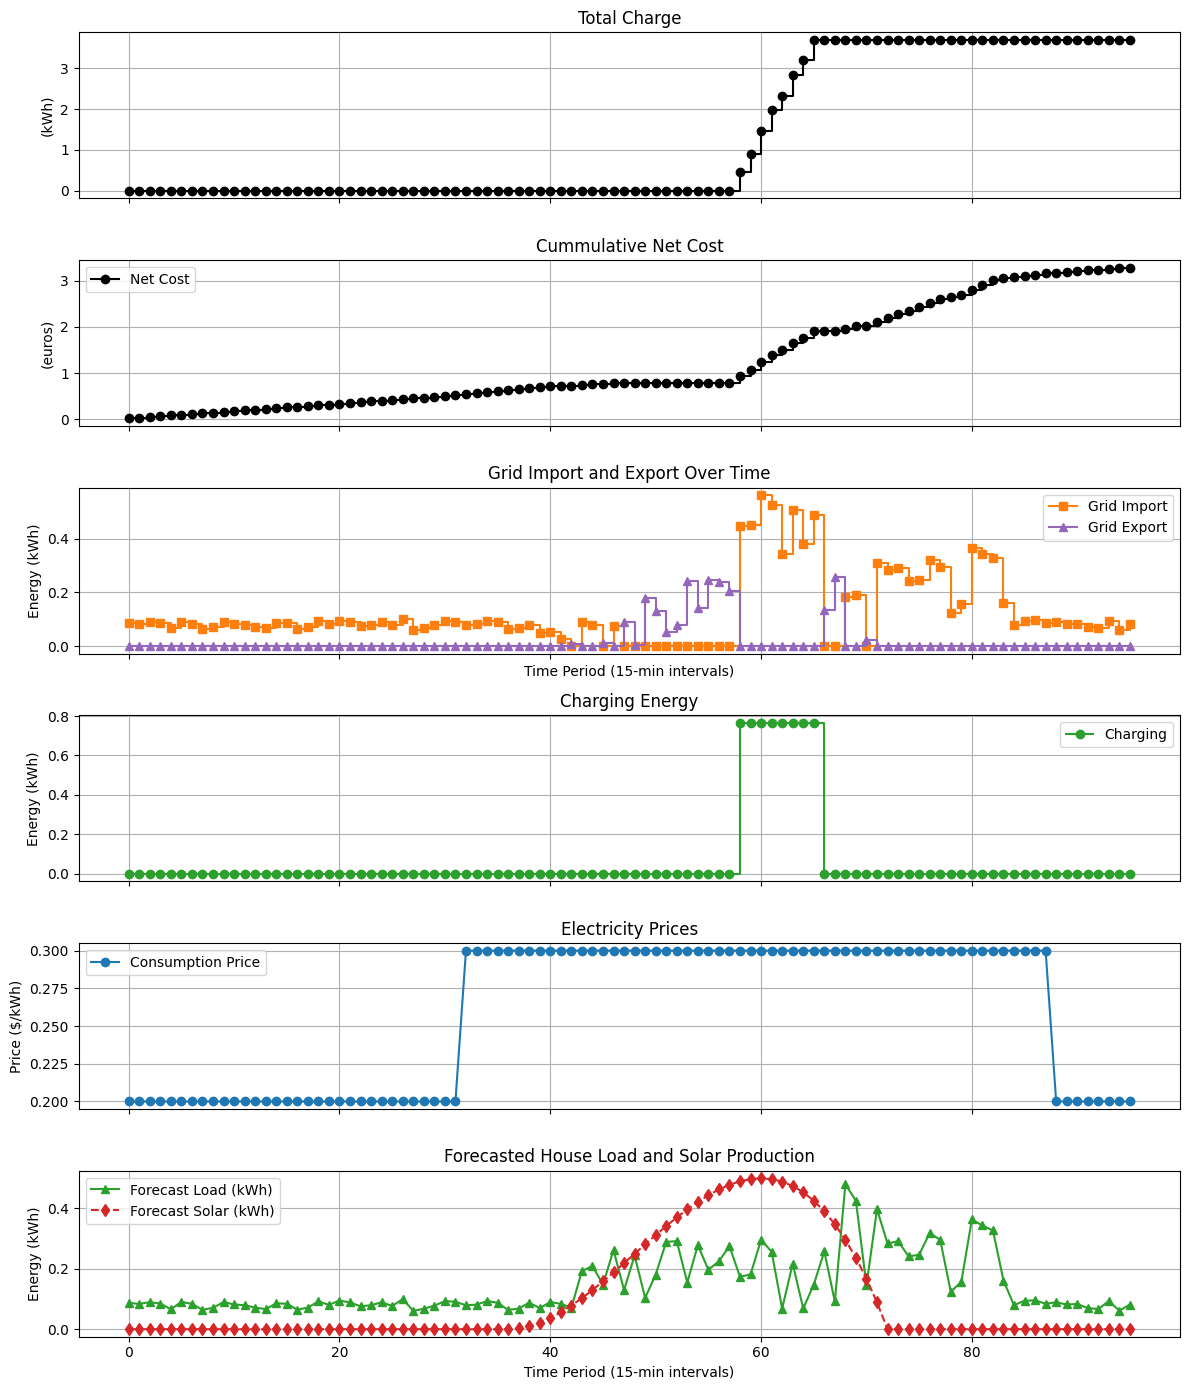

In [8]:
import matplotlib.pyplot as plt
import numpy as np


# Assuming that the following variables are defined from the HiGHS solution:
# time_periods: a list of time period indices (e.g., range(T))
# h: your solved HiGHS model, where h.variableValue(var) returns the optimal value for a given variable.
# Also assume that the following solution arrays have been extracted from the HiGHS solution:
grid_in_when_charging_solution = np.array([h.variableValue(grid_in_when_charging[t]) for t in time_periods])
grid_in_solution = np.array([h.variableValue(grid_in[t]) for t in time_periods])
grid_out_solution = np.array([h.variableValue(grid_out[t]) for t in time_periods])
fob_solution = np.array([h.variableValue(grid_in[t])*(price_consumption[t]) for t in time_periods])
charge_solution = np.array([h.variableValue(charge[t]) for t in time_periods])
x_solution = np.array([h.variableValue(x[t]) for t in time_periods])

# ---------------------------
# Figure 1: EMS Results
# ---------------------------
fig1, axs1 = plt.subplots(6, 1, figsize=(12, 14), sharex=True)
i=-1

# Plot Cummulative cost
i+=1
axs1[i].step(time_periods, np.cumsum(grid_in_when_charging_solution), where='post', marker='o', linestyle='-', color='black')
axs1[i].set_ylabel("(kWh)")
axs1[i].set_title("Total Charge")
axs1[i].grid(True)

# Plot Cummulative cost
i+=1
axs1[i].step(time_periods, np.cumsum(fob_solution), where='post', marker='o', linestyle='-', color='black')
axs1[i].set_ylabel("(euros)")
axs1[i].set_title("Cummulative Net Cost")
axs1[i].grid(True)
axs1[i].legend(["Net Cost"])


# Plot Grid Import and Export
# Contracted energy per period (P_contract * delta_t)
i+=1
max_energy_per_period = P_contract * delta_t
axs1[i].step(time_periods, grid_in_solution, where='post', marker='s', linestyle='-', label="Grid Import", color='tab:orange')
axs1[i].step(time_periods, grid_out_solution,where='post',  marker='^', linestyle='-', label="Grid Export", color='tab:purple')
if np.max(grid_out_solution) >=max_energy_per_period or np.max(grid_in_solution) >=max_energy_per_period:
    axs1[i].axhline(max_energy_per_period, color='tab:red', linestyle='--', linewidth=2,
               label=f"Contracted Limit ({max_energy_per_period:.2f} kWh)")

axs1[i].set_xlabel("Time Period (15-min intervals)")
axs1[i].set_ylabel("Energy (kWh)")
axs1[i].set_title("Grid Import and Export Over Time")
axs1[i].grid(True)
axs1[i].legend()


# Plot the self consumption charging energy
i+=1
axs1[i].step(time_periods, charge_solution, where='post', marker='o', linestyle='-', color='tab:green', label="Charging")
axs1[i].set_ylabel("Energy (kWh)")
axs1[i].set_title("Charging Energy")
axs1[i].legend()
axs1[i].grid(True)

# Plot Electricity Prices (Consumption and Injection)
i+=1
axs1[i].plot(time_periods, price_consumption, marker='o', linestyle='-', color='tab:blue', label='Consumption Price')
axs1[i].set_ylabel("Price ($/kWh)")
axs1[i].set_title("Electricity Prices")
axs1[i].legend()
axs1[i].grid(True)

# Plot Forecasted House Load and Solar Production
i+=1
axs1[i].plot(time_periods, forecast_load, marker='^', linestyle='-', color='tab:green', label='Forecast Load (kWh)')
axs1[i].plot(time_periods, forecast_solar, marker='d', linestyle='--', color='tab:red', label='Forecast Solar (kWh)')
axs1[i].set_xlabel("Time Period (15-min intervals)")
axs1[i].set_ylabel("Energy (kWh)")
axs1[i].set_title("Forecasted House Load and Solar Production")
axs1[i].legend()
axs1[i].grid(True)

plt.tight_layout()
plt.show()